In [1]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

Setup Configuration

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
DCGAN_CONFIG = CONFIG["models"]["dcgan"]

SEED = GENERAL_CONFIG["random_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", GENERAL_CONFIG["project_name"])
print("Dataset:", GENERAL_CONFIG["dataset"])
print("Device:", device)
print("Noise Dimension:", DCGAN_CONFIG["noise_dim"])
print("Batch Size:", GENERAL_CONFIG["batch_size"])
print("Epochs:", DCGAN_CONFIG["epochs"])

Project: Generative Models Comparison
Dataset: Fashion-MNIST
Device: cpu
Noise Dimension: 100
Batch Size: 128
Epochs: 100


Load Dataset

In [3]:
dataset_path = DATA_DIR / "fashion_mnist" / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=False
)

X_train = dataset["train_images"]
X_val = dataset["val_images"]
X_test = dataset["test_images"]

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


Preprocessing

In [4]:
X_train = X_train.float() / 127.5 - 1.0
X_val = X_val.float() / 127.5 - 1.0
X_test = X_test.float() / 127.5 - 1.0

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nPixel Value Range:")
print("Minimum:", X_train.min().item())
print("Maximum:", X_train.max().item())

Training Shape: torch.Size([56000, 1, 28, 28])
Validation Shape: torch.Size([7000, 1, 28, 28])
Testing Shape: torch.Size([7000, 1, 28, 28])

Pixel Value Range:
Minimum: -1.0
Maximum: 1.0


DataLoader

In [5]:
BATCH_SIZE = GENERAL_CONFIG["batch_size"]

train_dataset = TensorDataset(X_train)
val_dataset = TensorDataset(X_val)
test_dataset = TensorDataset(X_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 438
Validation Batches: 55
Testing Batches: 55


Define DCGAN Generator

In [7]:
class DCGANGenerator(nn.Module):
    def __init__(self, config):
        super(DCGANGenerator, self).__init__()

        channels = config["generator_channels"]
        noise_dim = config["noise_dim"]

        self.project = nn.Linear(
            noise_dim,
            channels[0]
        )

        self.model = nn.Sequential(
            # 1x1 -> 7x7
            nn.ConvTranspose2d(
                channels[0],
                channels[1],
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(channels[1]),
            nn.ReLU(True),

            # 7x7 -> 14x14
            nn.ConvTranspose2d(
                channels[1],
                channels[1],
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(channels[1]),
            nn.ReLU(True),

            # 14x14 -> 28x28
            nn.ConvTranspose2d(
                channels[1],
                channels[-1],
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.Tanh()
        )

    def forward(self, noise):
        features = self.project(noise)
        features = features.view(-1, DCGAN_CONFIG["generator_channels"][0], 1, 1)

        return self.model(features)


generator = DCGANGenerator(DCGAN_CONFIG).to(device)

print(generator)

DCGANGenerator(
  (project): Linear(in_features=100, out_features=128, bias=True)
  (model): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)


Define DCGAN Discriminator

In [8]:
class DCGANDiscriminator(nn.Module):
    def __init__(self, config):
        super(DCGANDiscriminator, self).__init__()

        channels = config["discriminator_channels"]

        self.model = nn.Sequential(
            # 28x28 -> 14x14
            nn.Conv2d(
                channels[0],
                channels[1],
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 14x14 -> 7x7
            nn.Conv2d(
                channels[1],
                channels[2],
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(channels[2]),
            nn.LeakyReLU(0.2, inplace=True),

            # 7x7 -> 1x1
            nn.Conv2d(
                channels[2],
                1,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, images):
        output = self.model(images)
        return output.view(-1, 1)


discriminator = DCGANDiscriminator(DCGAN_CONFIG).to(device)

print(discriminator)

DCGANDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (6): Sigmoid()
  )
)


Setup Loss and Optimizers

In [9]:
criterion = nn.BCELoss()

LEARNING_RATE = DCGAN_CONFIG["learning_rate"]
BETAS = tuple(DCGAN_CONFIG["betas"])
NOISE_DIM = DCGAN_CONFIG["noise_dim"]
EPOCHS = DCGAN_CONFIG["epochs"]

generator_optimizer = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=BETAS
)

discriminator_optimizer = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=BETAS
)

print("Loss Function:", criterion)
print("Learning Rate:", LEARNING_RATE)
print("Adam Betas:", BETAS)
print("Noise Dimension:", NOISE_DIM)
print("Epochs:", EPOCHS)

Loss Function: BCELoss()
Learning Rate: 0.0002
Adam Betas: (0.5, 0.999)
Noise Dimension: 100
Epochs: 100


Test Model Architecture

In [10]:
# Test Generator
test_noise = torch.randn(8, NOISE_DIM).to(device)

with torch.no_grad():
    generated_images = generator(test_noise)

# Test Discriminator
with torch.no_grad():
    discriminator_output = discriminator(generated_images)

print("Noise Shape:", test_noise.shape)
print("Generated Images Shape:", generated_images.shape)
print("Discriminator Output Shape:", discriminator_output.shape)

print("\nGenerated Pixel Range:")
print("Minimum:", generated_images.min().item())
print("Maximum:", generated_images.max().item())

Noise Shape: torch.Size([8, 100])
Generated Images Shape: torch.Size([8, 1, 28, 28])
Discriminator Output Shape: torch.Size([8, 1])

Generated Pixel Range:
Minimum: -0.9999838471412659
Maximum: 0.9997882843017578


Prepare Training

In [11]:
generator_losses = []
discriminator_losses = []

fixed_noise = torch.randn(10, NOISE_DIM).to(device)

checkpoint_path = CHECKPOINTS_DIR / "dcgan.pth"

print("Fixed Noise Shape:", fixed_noise.shape)
print("Checkpoint Path:", checkpoint_path)

Fixed Noise Shape: torch.Size([10, 100])
Checkpoint Path: d:\generative-models-comparison\checkpoints\dcgan.pth


Train DCGAN

In [12]:
for epoch in range(EPOCHS):
    generator.train()
    discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for (real_images,) in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train Discriminator
        discriminator_optimizer.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        discriminator_optimizer.step()

        # Train Generator
        generator_optimizer.zero_grad()

        for p in discriminator.parameters():
            p.requires_grad = False

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        generated_images = generator(noise)

        output = discriminator(generated_images)
        g_loss = criterion(output, real_labels)

        g_loss.backward()
        generator_optimizer.step()

        for p in discriminator.parameters():
            p.requires_grad = True

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "generator_optimizer_state_dict": generator_optimizer.state_dict(),
            "discriminator_optimizer_state_dict": discriminator_optimizer.state_dict(),
            "generator_losses": generator_losses,
            "discriminator_losses": discriminator_losses
        }, checkpoint_path)

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Generator Loss: {avg_g_loss:.6f} "
            f"Discriminator Loss: {avg_d_loss:.6f}"
        )

Epoch [10/100] Generator Loss: 1.005430 Discriminator Loss: 0.589713
Epoch [20/100] Generator Loss: 1.075490 Discriminator Loss: 0.564907
Epoch [30/100] Generator Loss: 1.141600 Discriminator Loss: 0.539632
Epoch [40/100] Generator Loss: 1.208920 Discriminator Loss: 0.517302
Epoch [50/100] Generator Loss: 1.275986 Discriminator Loss: 0.500787
Epoch [60/100] Generator Loss: 1.345638 Discriminator Loss: 0.481893
Epoch [70/100] Generator Loss: 1.380444 Discriminator Loss: 0.470678
Epoch [80/100] Generator Loss: 1.426123 Discriminator Loss: 0.458410
Epoch [90/100] Generator Loss: 1.496194 Discriminator Loss: 0.444720
Epoch [100/100] Generator Loss: 1.552695 Discriminator Loss: 0.430480


Plot Training Curves


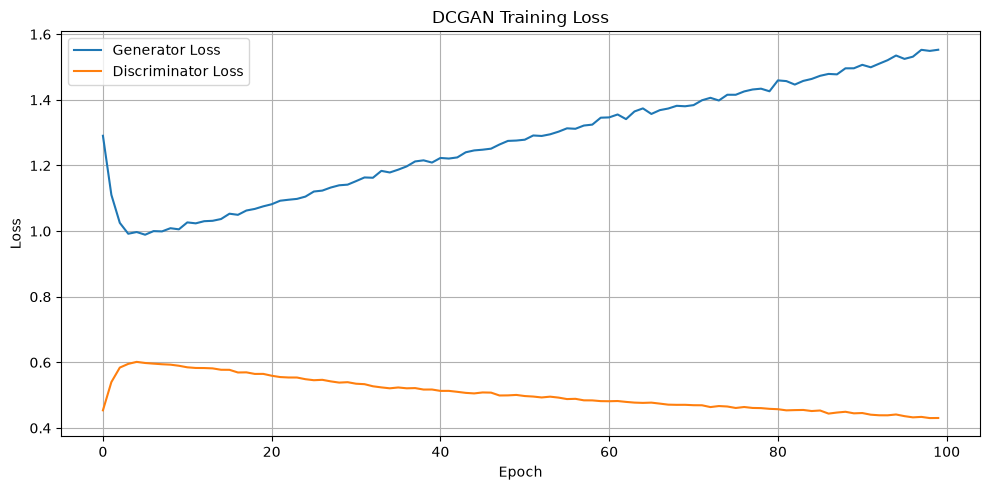

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")

plt.title("DCGAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(RESULTS_DIR / "dcgan_training_curves.png", dpi=100)
plt.show()

Generate Images

Generated Images Shape: torch.Size([10, 1, 28, 28])
Pixel Range:
Minimum: -1.0
Maximum: 0.9972139596939087


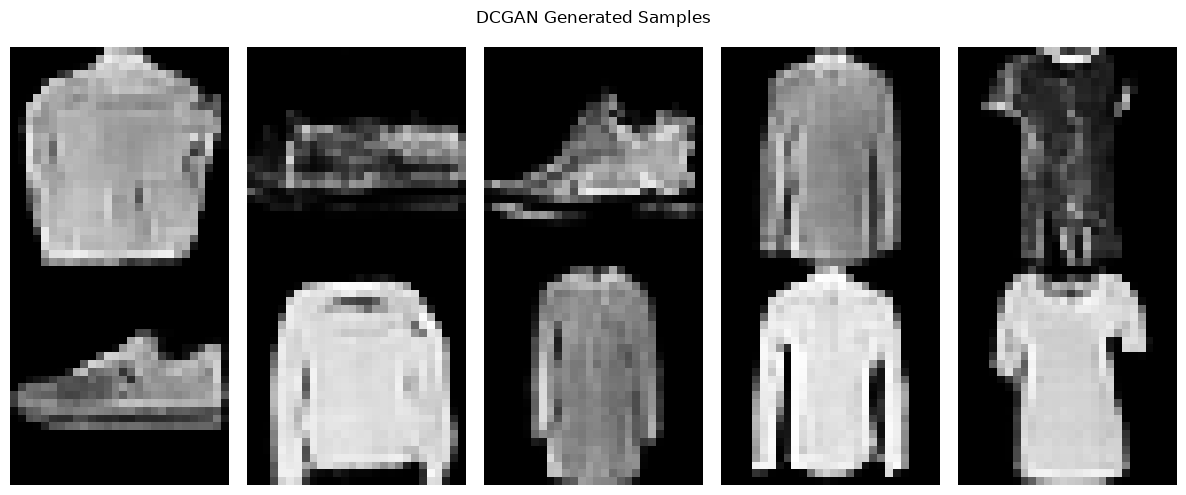

In [15]:
generator.eval()

with torch.no_grad():
    generated_images = generator(fixed_noise).cpu()

print("Generated Images Shape:", generated_images.shape)
print("Pixel Range:")
print("Minimum:", generated_images.min().item())
print("Maximum:", generated_images.max().item())

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = generated_images[i].squeeze()
    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")

plt.suptitle("DCGAN Generated Samples")
plt.tight_layout()

plt.savefig(RESULTS_DIR / "dcgan_generated_samples.png", dpi=100)
plt.show()

Save Generated Samples

In [17]:
torch.save(
    generated_images,
    RESULTS_DIR / "dcgan_generated_samples.pt"
)

Generate Fresh Samples

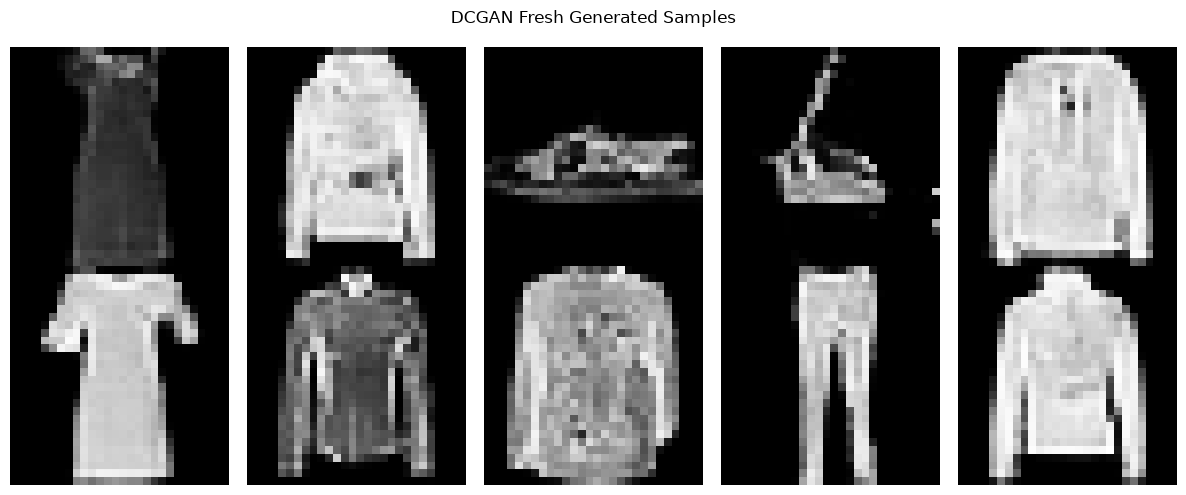

In [18]:
fresh_noise = torch.randn(10, NOISE_DIM).to(device)

generator.eval()

with torch.no_grad():
    fresh_images = generator(fresh_noise).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(fresh_images[i].squeeze(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")

plt.suptitle("DCGAN Fresh Generated Samples")
plt.tight_layout()

plt.savefig(RESULTS_DIR / "dcgan_fresh_generated_samples.png", dpi=100)
plt.show()